# Econ 4850 · Economic Analysis with Python
## Lecture 5: Practice Using the FRED API
Geoffrey Kam, Washington University in St. Louis · g.kam@wustl.edu · Spring 2025

**What you'll learn**

- How to get a FRED API key and use it safely, without ever writing it into your notebook.
- How to search FRED and download one or many data series with the `fredapi` package.
- How to clean, combine and inspect the downloaded series (missing values, renaming columns).
- How to plot state unemployment rates around the COVID-19 recession.

This lecture follows the Kaggle grandmaster [Rob Mulla](https://www.youtube.com/watch?v=R67XuYc9NQ4&t=1154s).

## Installation

Install the `fredapi` package once (you can skip this if it is already installed).

In [ ]:
%pip install fredapi

## Setup

In [1]:
import time

import pandas as pd
import matplotlib.pyplot as plt  # standard plotting
import plotly.express as px  # interactive plotting
import seaborn as sns

# Display options
pd.set_option("display.max_columns", 500)
pd.set_option("display.max_rows", 10)

# Plot style
plt.style.use("ggplot")
color_pal = plt.rcParams["axes.prop_cycle"].by_key()["color"]  # list of the style's colors
plt.rcParams["figure.figsize"] = (10, 5)

In [2]:
# Display plotly graphs in the notebook and in HTML exports;
# "notebook_connected" loads plotly.js from a CDN instead of embedding it
import plotly.io as pio
pio.renderers.default = "notebook_connected"

## Get Your API Key

1. Go to the [FRED website](https://fred.stlouisfed.org/docs/api/fred/) and create a free account.
2. Under `My Account` (top right corner), go to `API Keys` and request a key. The direct link is https://fred.stlouisfed.org/docs/api/api_key.html.
3. Store the key in the environment variable `FRED_API_KEY` instead of typing it into your notebook. On macOS or Linux, run this in a terminal (add the line to `~/.zshrc` or `~/.bashrc` to make it permanent), then restart Jupyter:

   ```bash
   export FRED_API_KEY="your_key_here"
   ```

   On Windows, run `setx FRED_API_KEY "your_key_here"` in a command prompt and open a new session.

You could also paste the key directly into the code (`api_key = "..."`), which is fine on your own computer, but **never publish or share a notebook or file that contains your key**.

In [3]:
import os

api_key = os.environ["FRED_API_KEY"]

## Using the FRED API

### Create the `Fred` Object

In [4]:
from fredapi import Fred

fred = Fred(api_key=api_key)

### Search for Economic Data

`fred.search` tells us which series are available. It returns a `DataFrame` with one row per series, indexed by the series ID.

In [5]:
ur_search = fred.search("unemployment rate")
ur_search

,id,realtime_start,realtime_end,title,observation_start,observation_end,frequency,frequency_short,units,units_short,seasonal_adjustment,seasonal_adjustment_short,last_updated,popularity,notes
series id,,,,,,,,,,,,,,,
UNRATE,UNRATE,2026-10-25,2026-10-25,Unemployment Rate,1948-01-01,2026-09-01,Monthly,M,Percent,%,Seasonally Adjusted,SA,2026-10-02 08:24:37-05:00,96,The unemployment rate represents the number of...
UNRATENSA,UNRATENSA,2026-10-25,2026-10-25,Unemployment Rate,1948-01-01,2026-09-01,Monthly,M,Percent,%,Not Seasonally Adjusted,NSA,2026-10-02 08:24:34-05:00,54,The unemployment rate represents the number of...
LNS14000006,LNS14000006,2026-10-25,2026-10-25,Unemployment Rate - Black or African American,1972-01-01,2026-09-01,Monthly,M,Percent,%,Seasonally Adjusted,SA,2026-10-02 08:25:54-05:00,65,The series comes from the 'Current Population ...
LNS14024887,LNS14024887,2026-10-25,2026-10-25,Unemployment Rate - 16-24 Yrs.,1948-01-01,2026-09-01,Monthly,M,Percent,%,Seasonally Adjusted,SA,2026-10-02 08:25:59-05:00,65,The series comes from the 'Current Population ...
NROU,NROU,2026-10-25,2026-10-25,Noncyclical Rate of Unemployment,1949-01-01,2036-10-01,Quarterly,Q,Percent,%,Not Seasonally Adjusted,NSA,2026-02-27 15:05:27-06:00,63,"Starting with the July, 2021 report: An Update..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
FLGADS9LFN,FLGADS9LFN,2026-10-25,2026-10-25,"Civilian Labor Force in Gadsden County, FL",1990-01-01,2026-08-01,Monthly,M,Persons,Persons,Not Seasonally Adjusted,NSA,2026-09-30 14:16:01-05:00,1,These data come from the Current Population Su...
CTTOLL3LFN,CTTOLL3LFN,2026-10-25,2026-10-25,"Civilian Labor Force in Tolland County, CT",1990-01-01,2024-12-01,Monthly,M,Persons,Persons,Not Seasonally Adjusted,NSA,2025-02-05 10:20:49-06:00,1,These data come from the Current Population Su...
COBACA9LFN,COBACA9LFN,2026-10-25,2026-10-25,"Civilian Labor Force in Baca County, CO",1990-01-01,2026-08-01,Monthly,M,Persons,Persons,Not Seasonally Adjusted,NSA,2026-09-30 14:16:10-05:00,1,These data come from the Current Population Su...


### Pull Data

Download a single series by its ID. `UNRATE` is the US civilian unemployment rate.

In [6]:
unrate = fred.get_series("UNRATE")
unrate

1948-01-01    3.4
1948-02-01    3.8
1948-03-01    4.0
1948-04-01    3.9
1948-05-01    3.5
             ... 
2026-05-01    4.3
2026-06-01    4.2
2026-07-01    4.1
2026-08-01    4.1
2026-09-01    4.2
Length: 945, dtype: float64

`lw` sets the line width and `alpha` the transparency (0 is fully transparent, 1 fully opaque). Try changing them.

<Axes: title={'center': 'Unemployment Rate (%)'}>

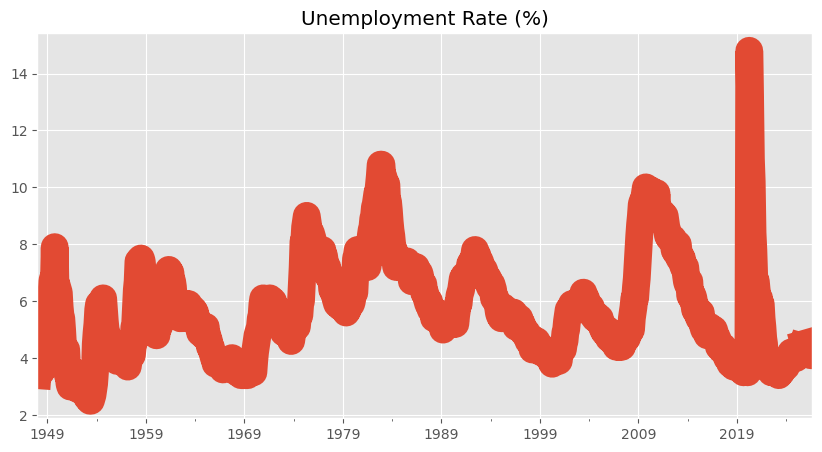

In [7]:
unrate.plot(title="Unemployment Rate (%)", lw=20, alpha=1)

## Pull and Join Multiple Data Series

Search for monthly unemployment rates by state.

In [8]:
unemp_state = fred.search("unemployment rate state", filter=("frequency", "Monthly"), limit=2000)
unemp_state

,id,realtime_start,realtime_end,title,observation_start,observation_end,frequency,frequency_short,units,units_short,seasonal_adjustment,seasonal_adjustment_short,last_updated,popularity,notes
series id,,,,,,,,,,,,,,,
UNRATE,UNRATE,2026-10-25,2026-10-25,Unemployment Rate,1948-01-01,2026-09-01,Monthly,M,Percent,%,Seasonally Adjusted,SA,2026-10-02 08:24:37-05:00,96,The unemployment rate represents the number of...
UNRATENSA,UNRATENSA,2026-10-25,2026-10-25,Unemployment Rate,1948-01-01,2026-09-01,Monthly,M,Percent,%,Not Seasonally Adjusted,NSA,2026-10-02 08:24:34-05:00,54,The unemployment rate represents the number of...
U6RATE,U6RATE,2026-10-25,2026-10-25,"Total Unemployed, Plus All Persons Marginally ...",1994-01-01,2026-09-01,Monthly,M,Percent,%,Seasonally Adjusted,SA,2026-10-02 08:24:34-05:00,73,The series comes from the 'Current Population ...
U6RATENSA,U6RATENSA,2026-10-25,2026-10-25,"Total Unemployed, Plus All Persons Marginally ...",1994-01-01,2026-09-01,Monthly,M,Percent,%,Not Seasonally Adjusted,NSA,2026-10-02 08:24:32-05:00,21,The series comes from the 'Current Population ...
UEMP27OV,UEMP27OV,2026-10-25,2026-10-25,Number Unemployed for 27 Weeks & over,1948-01-01,2026-09-01,Monthly,M,Thousands of Persons,Thous. of Persons,Seasonally Adjusted,SA,2026-10-02 08:24:32-05:00,67,The series comes from the 'Current Population ...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
LAUCN200730000000005,LAUCN200730000000005,2026-10-25,2026-10-25,"Employed Persons in Greenwood County, KS",1990-01-01,2026-08-01,Monthly,M,Persons,Persons,Not Seasonally Adjusted,NSA,2026-09-30 14:11:06-05:00,1,These data come from the Current Population Su...
LAUCN311130000000005,LAUCN311130000000005,2026-10-25,2026-10-25,"Employed Persons in Logan County, NE",1990-01-01,2026-08-01,Monthly,M,Persons,Persons,Not Seasonally Adjusted,NSA,2026-09-30 14:09:42-05:00,1,These data come from the Current Population Su...
LAUCN170290000000005,LAUCN170290000000005,2026-10-25,2026-10-25,"Employed Persons in Coles County, IL",1990-01-01,2026-08-01,Monthly,M,Persons,Persons,Not Seasonally Adjusted,NSA,2026-09-30 14:12:10-05:00,1,These data come from the Current Population Su...


Keep only seasonally adjusted series measured in percent.

In [9]:
unemp_state.query('seasonal_adjustment == "Seasonally Adjusted" & units == "Percent"', inplace=True)
unemp_state

,id,realtime_start,realtime_end,title,observation_start,observation_end,frequency,frequency_short,units,units_short,seasonal_adjustment,seasonal_adjustment_short,last_updated,popularity,notes
series id,,,,,,,,,,,,,,,
UNRATE,UNRATE,2026-10-25,2026-10-25,Unemployment Rate,1948-01-01,2026-09-01,Monthly,M,Percent,%,Seasonally Adjusted,SA,2026-10-02 08:24:37-05:00,96,The unemployment rate represents the number of...
U6RATE,U6RATE,2026-10-25,2026-10-25,"Total Unemployed, Plus All Persons Marginally ...",1994-01-01,2026-09-01,Monthly,M,Percent,%,Seasonally Adjusted,SA,2026-10-02 08:24:34-05:00,73,The series comes from the 'Current Population ...
LNS14000006,LNS14000006,2026-10-25,2026-10-25,Unemployment Rate - Black or African American,1972-01-01,2026-09-01,Monthly,M,Percent,%,Seasonally Adjusted,SA,2026-10-02 08:25:54-05:00,65,The series comes from the 'Current Population ...
LNS14024887,LNS14024887,2026-10-25,2026-10-25,Unemployment Rate - 16-24 Yrs.,1948-01-01,2026-09-01,Monthly,M,Percent,%,Seasonally Adjusted,SA,2026-10-02 08:25:59-05:00,65,The series comes from the 'Current Population ...
CAUR,CAUR,2026-10-25,2026-10-25,Unemployment Rate in California,1976-01-01,2026-09-01,Monthly,M,Percent,%,Seasonally Adjusted,SA,2026-10-20 09:38:54-05:00,58,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ARUR,ARUR,2026-10-25,2026-10-25,Unemployment Rate in Arkansas,1976-01-01,2026-09-01,Monthly,M,Percent,%,Seasonally Adjusted,SA,2026-10-20 09:38:35-05:00,25,None
MDUR,MDUR,2026-10-25,2026-10-25,Unemployment Rate in Maryland,1976-01-01,2026-09-01,Monthly,M,Percent,%,Seasonally Adjusted,SA,2026-10-20 09:48:34-05:00,22,None
LNS14032183,LNS14032183,2026-10-25,2026-10-25,Unemployment Rate - Asian,2003-01-01,2026-09-01,Monthly,M,Percent,%,Seasonally Adjusted,SA,2026-10-02 08:25:51-05:00,15,The series comes from the 'Current Population ...


Keep series whose title contains "Unemployment Rate in", excluding Census regions and divisions.

In [10]:
is_state_rate = (unemp_state["title"].str.contains("Unemployment Rate in")
                 & ~unemp_state["title"].str.contains("Census"))
unemp_df = unemp_state.loc[is_state_rate]
unemp_df

,id,realtime_start,realtime_end,title,observation_start,observation_end,frequency,frequency_short,units,units_short,seasonal_adjustment,seasonal_adjustment_short,last_updated,popularity,notes
series id,,,,,,,,,,,,,,,
CAUR,CAUR,2026-10-25,2026-10-25,Unemployment Rate in California,1976-01-01,2026-09-01,Monthly,M,Percent,%,Seasonally Adjusted,SA,2026-10-20 09:38:54-05:00,58,None
ALUR,ALUR,2026-10-25,2026-10-25,Unemployment Rate in Alabama,1976-01-01,2026-09-01,Monthly,M,Percent,%,Seasonally Adjusted,SA,2026-10-20 09:41:08-05:00,45,None
TXUR,TXUR,2026-10-25,2026-10-25,Unemployment Rate in Texas,1976-01-01,2026-09-01,Monthly,M,Percent,%,Seasonally Adjusted,SA,2026-10-20 09:54:25-05:00,54,None
FLUR,FLUR,2026-10-25,2026-10-25,Unemployment Rate in Florida,1976-01-01,2026-09-01,Monthly,M,Percent,%,Seasonally Adjusted,SA,2026-10-20 09:44:51-05:00,48,None
GAUR,GAUR,2026-10-25,2026-10-25,Unemployment Rate in Georgia,1976-01-01,2026-09-01,Monthly,M,Percent,%,Seasonally Adjusted,SA,2026-10-20 09:45:35-05:00,37,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
WVUR,WVUR,2026-10-25,2026-10-25,Unemployment Rate in West Virginia,1976-01-01,2026-09-01,Monthly,M,Percent,%,Seasonally Adjusted,SA,2026-10-20 09:54:34-05:00,27,None
CTUR,CTUR,2026-10-25,2026-10-25,Unemployment Rate in Connecticut,1976-01-01,2026-09-01,Monthly,M,Percent,%,Seasonally Adjusted,SA,2026-10-20 09:38:59-05:00,26,None
OKUR,OKUR,2026-10-25,2026-10-25,Unemployment Rate in Oklahoma,1976-01-01,2026-09-01,Monthly,M,Percent,%,Seasonally Adjusted,SA,2026-10-20 09:50:05-05:00,26,None


`fred.search` returns at most `limit` results, ranked by relevance, and our search hit the limit of 2000. So `unemp_df` need not contain all 50 states; `len(unemp_df)` tells you how many series you have.

We download each series by its series ID, which is the index of `unemp_df`.

In [11]:
unemp_df.index

Index(['CAUR', 'ALUR', 'TXUR', 'FLUR', 'GAUR', 'NYUR', 'LAUR', 'MSUR', 'MIUR',
       'ILUR', 'OHUR', 'PAUR', 'MOUR', 'VAUR', 'MAUR', 'NJUR', 'NCUR', 'WIUR',
       'ORUR', 'TNUR', 'MNUR', 'KYUR', 'WAUR', 'DCUR', 'AZUR', 'COUR',
       'LASMT534266000000003', 'PRUR', 'LASMT261982000000003', 'NVUR', 'SCUR',
       'INUR', 'WVUR', 'CTUR', 'OKUR', 'ARUR', 'MDUR'],
      dtype='object', name='series id')

Rob Mulla downloads each series, turns it into a one-column `DataFrame`, collects these in a list, and concatenates them at the end:

```python
all_results = []
for state_id in unemp_df.index:
    results = fred.get_series(state_id)
    results = results.to_frame(name=state_id)
    all_results.append(results)
all_results = pd.concat(all_results, axis=1)
```

I suggest a simpler approach: create an empty `DataFrame` and add each series as a new column. We pause briefly between requests to be polite to the FRED server.

In [12]:
raw_results = pd.DataFrame()
for state_id in unemp_df.index:
    print(state_id)
    raw_results[state_id] = fred.get_series(state_id)
    time.sleep(0.5)

CAUR


ALUR


TXUR


FLUR


GAUR


...

WVUR


CTUR


OKUR


ARUR


MDUR


Check the result, and keep an untouched copy so that we do not have to download everything again if we make a mistake below.

In [13]:
raw_results

,CAUR,ALUR,TXUR,FLUR,GAUR,NYUR,LAUR,MSUR,MIUR,ILUR,OHUR,PAUR,MOUR,VAUR,MAUR,NJUR,NCUR,WIUR,ORUR,TNUR,MNUR,KYUR,WAUR,DCUR,AZUR,COUR,LASMT534266000000003,PRUR,LASMT261982000000003,NVUR,SCUR,INUR,WVUR,CTUR,OKUR,ARUR,MDUR
1976-01-01,9.2,6.7,5.8,9.6,8.4,10.3,6.3,6.6,9.9,6.6,8.1,8.1,6.0,6.0,10.6,10.2,6.5,5.8,9.5,6.0,5.9,5.6,8.5,8.8,10.2,5.8,NaN,19.6,NaN,9.2,7.3,6.6,7.4,9.7,5.8,7.3,6.5
1976-02-01,9.2,6.6,5.8,9.7,8.4,10.3,6.3,6.6,9.9,6.6,8.1,8.1,6.0,6.0,10.6,10.2,6.5,5.8,9.5,6.0,5.9,5.6,8.5,8.8,10.2,5.8,NaN,19.5,NaN,9.2,7.3,6.6,7.4,9.7,5.8,7.3,6.5
1976-03-01,9.1,6.6,5.9,9.6,8.3,10.2,6.3,6.6,9.9,6.6,8.1,8.1,6.0,6.0,10.6,10.2,6.5,5.8,9.4,6.0,5.8,5.6,8.5,8.7,10.2,5.7,NaN,19.3,NaN,9.2,7.3,6.5,7.4,9.7,5.8,7.3,6.5
1976-04-01,9.0,6.5,5.9,9.5,8.2,10.2,6.4,6.4,9.8,6.6,7.9,8.1,6.0,5.9,10.4,10.3,6.3,5.7,9.3,6.0,5.7,5.6,8.5,8.6,10.0,5.6,NaN,19.0,NaN,9.0,7.1,6.3,7.4,9.6,5.7,7.2,6.5
1976-05-01,8.9,6.4,6.0,9.3,8.1,10.2,6.5,6.3,9.6,6.6,7.8,8.1,6.0,5.8,10.1,10.3,6.1,5.6,9.1,5.9,5.6,5.5,8.5,8.5,9.8,5.6,NaN,18.9,NaN,8.8,7.0,6.0,7.4,9.4,5.7,7.1,6.6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-05-01,5.3,3.0,4.3,4.8,3.4,4.6,4.5,3.8,5.1,5.1,3.7,4.2,3.8,3.8,4.5,4.7,3.7,3.4,5.2,3.6,4.4,4.5,5.2,6.1,4.8,3.9,5.4,5.6,5.3,5.2,4.6,3.3,4.3,5.1,4.1,4.2,4.4
2026-06-01,5.2,3.2,4.4,4.7,3.4,4.6,4.4,3.8,5.0,5.1,3.6,4.1,3.7,3.8,4.4,4.5,3.6,3.3,5.2,3.5,4.4,4.7,5.2,6.0,4.9,3.9,5.2,5.8,5.4,5.1,4.4,3.3,4.2,5.2,4.2,4.1,4.3
2026-07-01,5.1,3.4,4.5,4.6,3.3,4.4,4.4,3.6,4.9,4.9,3.4,3.9,3.6,3.7,4.4,4.4,3.6,3.3,5.2,3.4,4.3,4.7,5.0,5.9,4.9,3.9,5.1,6.0,5.3,5.0,4.2,3.3,4.1,5.2,4.3,4.0,4.2
2026-08-01,5.1,3.4,4.4,4.5,3.2,4.3,4.2,3.4,5.0,4.7,3.3,3.7,3.5,3.6,4.3,4.3,3.5,3.2,5.1,3.4,4.4,4.7,4.9,5.7,4.9,4.0,4.9,6.1,5.4,4.8,4.1,3.3,4.0,5.1,4.3,3.9,4.1


In [14]:
all_results = raw_results.copy()

### Drop Unnecessary Series

The search can also return a few metropolitan-area series. In FRED, their IDs begin with `LASMT` (Local Area Unemployment Statistics, seasonally adjusted, metropolitan area). We drop every such column. Because the search results change over time, we use this rule instead of a hard-coded list of IDs.

In [15]:
all_results.columns

Index(['CAUR', 'ALUR', 'TXUR', 'FLUR', 'GAUR', 'NYUR', 'LAUR', 'MSUR', 'MIUR',
       'ILUR', 'OHUR', 'PAUR', 'MOUR', 'VAUR', 'MAUR', 'NJUR', 'NCUR', 'WIUR',
       'ORUR', 'TNUR', 'MNUR', 'KYUR', 'WAUR', 'DCUR', 'AZUR', 'COUR',
       'LASMT534266000000003', 'PRUR', 'LASMT261982000000003', 'NVUR', 'SCUR',
       'INUR', 'WVUR', 'CTUR', 'OKUR', 'ARUR', 'MDUR'],
      dtype='object')

In [16]:
metro_ids = [series_id for series_id in all_results.columns if series_id.startswith("LASMT")]
all_results = all_results.drop(columns=metro_ids)
metro_ids

['LASMT534266000000003', 'LASMT261982000000003']

In [17]:
all_results.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 609 entries, 1976-01-01 to 2026-09-01
Data columns (total 35 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   CAUR    608 non-null    float64
 1   ALUR    608 non-null    float64
 2   TXUR    608 non-null    float64
 3   FLUR    608 non-null    float64
 4   GAUR    608 non-null    float64
 5   NYUR    608 non-null    float64
 6   LAUR    608 non-null    float64
 7   MSUR    608 non-null    float64
 8   MIUR    608 non-null    float64
 9   ILUR    608 non-null    float64
 10  OHUR    608 non-null    float64
 11  PAUR    608 non-null    float64
 12  MOUR    608 non-null    float64
 13  VAUR    608 non-null    float64
 14  MAUR    608 non-null    float64
 15  NJUR    608 non-null    float64
 16  NCUR    608 non-null    float64
 17  WIUR    608 non-null    float64
 18  ORUR    608 non-null    float64
 19  TNUR    608 non-null    float64
 20  MNUR    608 non-null    float64
 21  KYUR    608 non-null

In [18]:
all_results.describe()

,CAUR,ALUR,TXUR,FLUR,GAUR,NYUR,LAUR,MSUR,MIUR,ILUR,OHUR,PAUR,MOUR,VAUR,MAUR,NJUR,NCUR,WIUR,ORUR,TNUR,MNUR,KYUR,WAUR,DCUR,AZUR,COUR,PRUR,NVUR,SCUR,INUR,WVUR,CTUR,OKUR,ARUR,MDUR
count,608.000000,608.00000,608.000000,608.000000,608.000000,608.000000,608.000000,608.000000,608.000000,608.000000,608.000000,608.000000,608.000000,608.000000,608.000000,608.000000,608.000000,608.000000,608.000000,608.000000,608.000000,608.000000,608.000000,608.000000,608.000000,608.000000,607.00000,608.000000,608.000000,608.000000,608.000000,608.000000,608.000000,608.000000,608.000000
mean,7.073684,6.54523,5.847204,5.951645,5.651974,6.346053,6.781414,7.050000,7.531579,6.690132,6.414309,6.198355,5.615296,4.480263,5.434868,6.152303,5.587336,5.143421,6.661020,6.016776,4.666776,6.389967,6.603618,7.302467,6.064309,5.195066,13.75799,6.564474,6.063980,5.746546,7.609539,5.315625,4.810855,6.002303,5.048849
std,2.160869,2.69326,1.466336,2.103695,1.829827,1.852498,2.218523,2.178122,3.078595,2.083994,2.189328,1.810157,1.767586,1.354317,1.933789,2.045092,2.030919,1.921462,2.059281,2.171331,1.421411,2.041888,1.987586,1.559974,1.884601,1.748619,4.48131,2.747032,2.099659,2.354481,3.011632,1.853712,1.451369,1.744370,1.415459
min,3.800000,2.30000,3.400000,2.800000,3.000000,3.800000,3.500000,2.800000,3.200000,3.600000,3.300000,3.500000,2.400000,2.200000,2.700000,3.100000,3.200000,2.600000,3.400000,3.200000,2.200000,4.000000,3.600000,4.000000,3.400000,2.400000,5.40000,3.900000,2.400000,2.700000,3.600000,2.100000,2.900000,2.900000,1.900000
25%,5.300000,4.60000,4.600000,4.375000,4.400000,4.700000,5.300000,5.700000,5.000000,5.075000,4.800000,4.800000,4.375000,3.400000,3.975000,4.500000,4.000000,3.600000,5.200000,4.600000,3.700000,4.900000,5.000000,6.000000,4.700000,3.800000,10.95000,4.800000,4.500000,4.000000,5.300000,3.900000,3.700000,4.800000,4.000000
50%,6.700000,6.15000,5.700000,5.600000,5.400000,6.200000,6.400000,6.500000,7.100000,6.200000,5.850000,5.700000,5.500000,4.300000,5.000000,5.800000,5.100000,4.700000,6.100000,5.500000,4.400000,5.700000,6.200000,7.300000,5.600000,5.200000,13.80000,5.550000,5.900000,5.200000,6.800000,5.100000,4.500000,5.700000,4.800000
75%,8.325000,7.60000,6.800000,7.125000,6.400000,7.625000,7.500000,8.400000,9.100000,8.025000,7.500000,7.500000,6.500000,5.400000,6.700000,7.400000,6.300000,6.025000,8.125000,7.100000,5.425000,7.725000,7.700000,8.500000,6.900000,6.200000,16.70000,7.425000,6.900000,6.600000,9.150000,6.400000,5.700000,7.300000,6.100000
max,16.100000,14.70000,12.800000,14.100000,12.500000,16.700000,13.500000,15.600000,22.700000,18.300000,16.500000,16.100000,11.600000,11.900000,17.800000,15.400000,14.200000,14.100000,13.700000,15.700000,11.100000,16.700000,17.100000,11.300000,13.800000,11.700000,24.00000,30.500000,11.700000,16.900000,18.300000,11.900000,12.500000,10.200000,9.000000


### Missing Values

Count the missing values in each month (row) and in each series (column).

<Axes: >

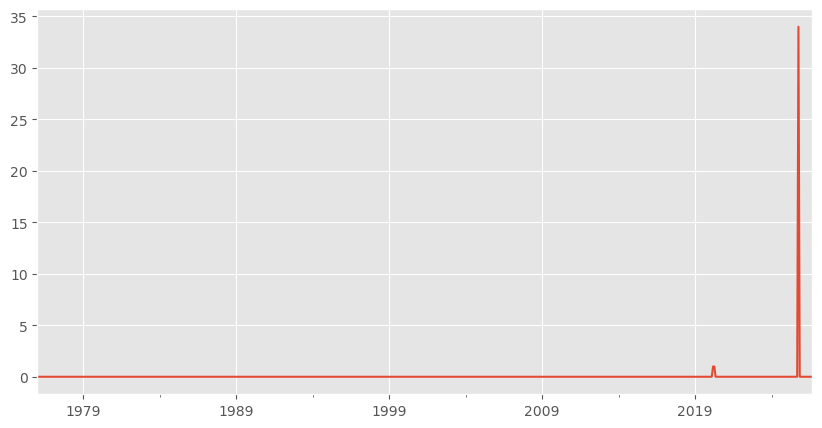

In [19]:
all_results.isna().sum(axis=1).plot()

<Axes: >

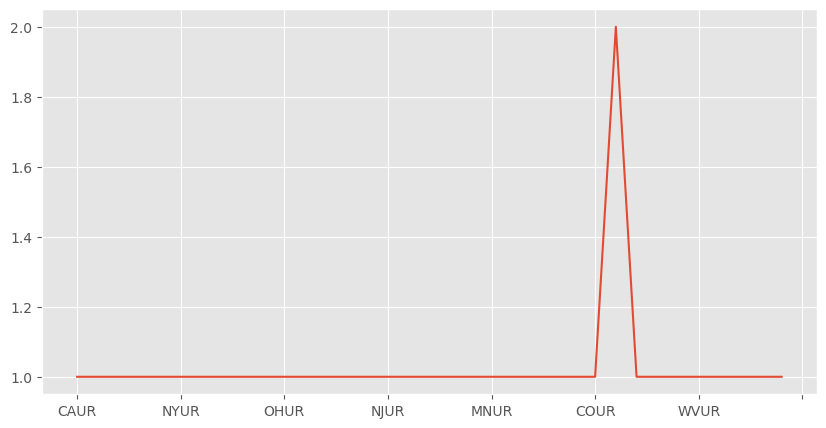

In [20]:
all_results.isna().sum(axis=0).plot()

We can also plot missing values on a 2D map: each column is a series, each row a month, and highlighted cells are missing.

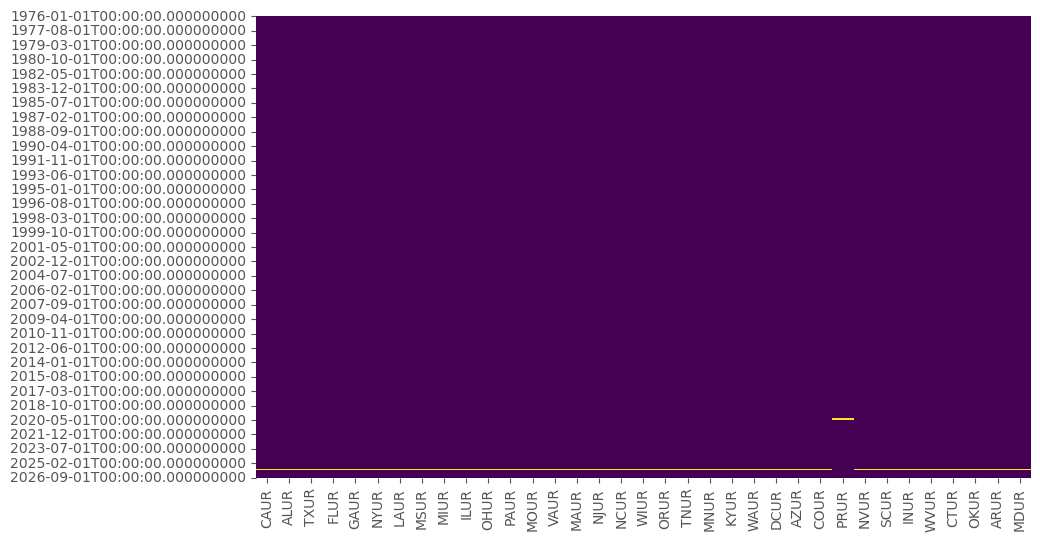

In [21]:
plt.figure(figsize=(10, 6))
sns.heatmap(all_results.isna(), cmap="viridis", cbar=False)
plt.show()

`dropna(axis=0)` drops a month for *every* series as soon as *one* series is missing it. The map shows that the Puerto Rico series (`PRUR`) has gaps the state series do not have; when these notes were built, these included March and April 2020, the first two months of the COVID-19 unemployment spike. To keep those months, drop Puerto Rico first, then drop every remaining month with a missing value, and check the map again.

In [22]:
all_results = all_results.drop(columns="PRUR", errors="ignore")
all_results.dropna(axis=0, inplace=True)

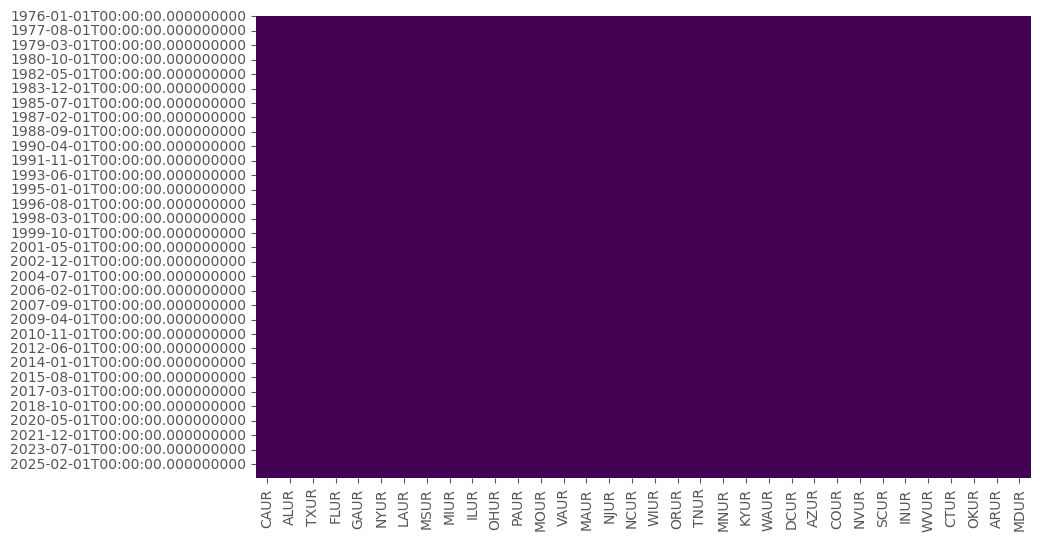

In [23]:
plt.figure(figsize=(10, 6))
sns.heatmap(all_results.isna(), cmap="viridis", cbar=False)
plt.show()

An interactive plot of all series takes a single command:

In [24]:
fig = px.line(all_results)
fig.show()

## COVID-19 Unemployment

Unemployment rates by state in May 2020:

<Axes: title={'center': 'Unemployment Rate by State in May 2020 (%)'}>

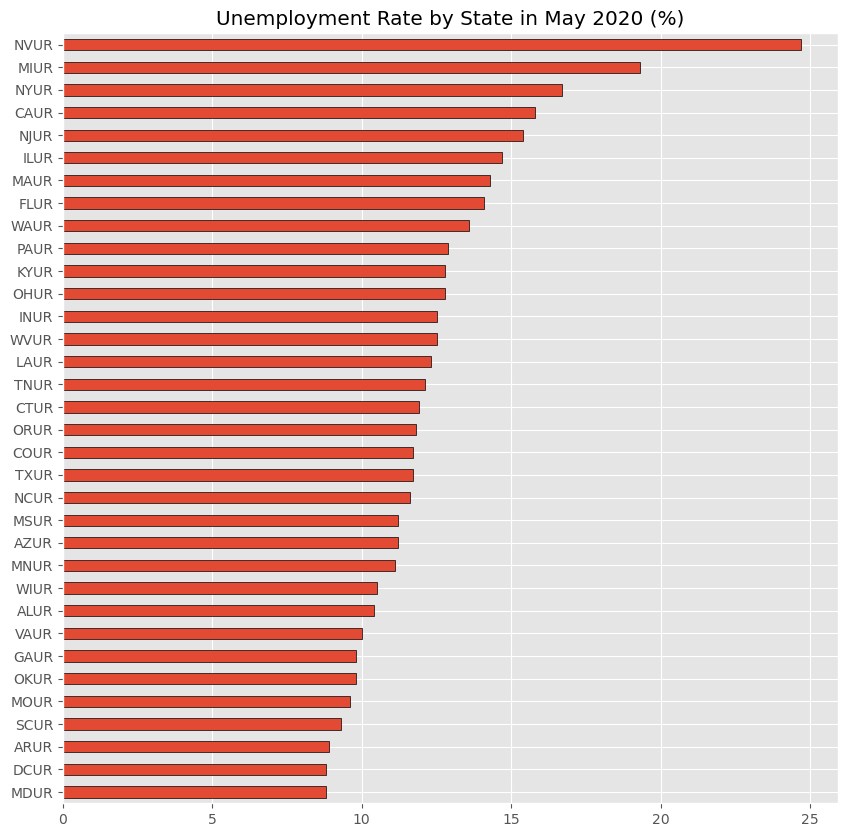

In [25]:
all_results.loc["2020-05-01"].sort_values().plot(
    kind="barh",
    figsize=(10, 10),
    title="Unemployment Rate by State in May 2020 (%)",
    legend=False,
    edgecolor="black",
)

The bars are labeled by series ID, which is hard to read. Build a dictionary that maps each series ID to its state name, using the titles from the search results.

In [26]:
unemp_df

,id,realtime_start,realtime_end,title,observation_start,observation_end,frequency,frequency_short,units,units_short,seasonal_adjustment,seasonal_adjustment_short,last_updated,popularity,notes
series id,,,,,,,,,,,,,,,
CAUR,CAUR,2026-10-25,2026-10-25,Unemployment Rate in California,1976-01-01,2026-09-01,Monthly,M,Percent,%,Seasonally Adjusted,SA,2026-10-20 09:38:54-05:00,58,None
ALUR,ALUR,2026-10-25,2026-10-25,Unemployment Rate in Alabama,1976-01-01,2026-09-01,Monthly,M,Percent,%,Seasonally Adjusted,SA,2026-10-20 09:41:08-05:00,45,None
TXUR,TXUR,2026-10-25,2026-10-25,Unemployment Rate in Texas,1976-01-01,2026-09-01,Monthly,M,Percent,%,Seasonally Adjusted,SA,2026-10-20 09:54:25-05:00,54,None
FLUR,FLUR,2026-10-25,2026-10-25,Unemployment Rate in Florida,1976-01-01,2026-09-01,Monthly,M,Percent,%,Seasonally Adjusted,SA,2026-10-20 09:44:51-05:00,48,None
GAUR,GAUR,2026-10-25,2026-10-25,Unemployment Rate in Georgia,1976-01-01,2026-09-01,Monthly,M,Percent,%,Seasonally Adjusted,SA,2026-10-20 09:45:35-05:00,37,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
WVUR,WVUR,2026-10-25,2026-10-25,Unemployment Rate in West Virginia,1976-01-01,2026-09-01,Monthly,M,Percent,%,Seasonally Adjusted,SA,2026-10-20 09:54:34-05:00,27,None
CTUR,CTUR,2026-10-25,2026-10-25,Unemployment Rate in Connecticut,1976-01-01,2026-09-01,Monthly,M,Percent,%,Seasonally Adjusted,SA,2026-10-20 09:38:59-05:00,26,None
OKUR,OKUR,2026-10-25,2026-10-25,Unemployment Rate in Oklahoma,1976-01-01,2026-09-01,Monthly,M,Percent,%,Seasonally Adjusted,SA,2026-10-20 09:50:05-05:00,26,None


In [27]:
id_to_state = unemp_df["title"].str.replace("Unemployment Rate in ", "").to_dict()
id_to_state

{'CAUR': 'California',
 'ALUR': 'Alabama',
 'TXUR': 'Texas',
 'FLUR': 'Florida',
 'GAUR': 'Georgia',
 'NYUR': 'New York',
 'LAUR': 'Louisiana',
 'MSUR': 'Mississippi',
 'MIUR': 'Michigan',
 'ILUR': 'Illinois',
 'OHUR': 'Ohio',
 'PAUR': 'Pennsylvania',
 'MOUR': 'Missouri',
 'VAUR': 'Virginia',
 'MAUR': 'Massachusetts',
 'NJUR': 'New Jersey',
 'NCUR': 'North Carolina',
 'WIUR': 'Wisconsin',
 'ORUR': 'Oregon',
 'TNUR': 'Tennessee',
 'MNUR': 'Minnesota',
 'KYUR': 'Kentucky',
 'WAUR': 'Washington',
 'DCUR': 'the District of Columbia',
 'AZUR': 'Arizona',
 'COUR': 'Colorado',
 'LASMT534266000000003': 'Seattle-Tacoma-Bellevue, WA (MSA)',
 'PRUR': 'Puerto Rico',
 'LASMT261982000000003': 'Detroit-Warren-Dearborn, MI (MSA)',
 'NVUR': 'Nevada',
 'SCUR': 'South Carolina',
 'INUR': 'Indiana',
 'WVUR': 'West Virginia',
 'CTUR': 'Connecticut',
 'OKUR': 'Oklahoma',
 'ARUR': 'Arkansas',
 'MDUR': 'Maryland'}

Replace the column names (series IDs) with state names.

In [28]:
all_results = all_results.rename(columns=id_to_state)
all_results

,California,Alabama,Texas,Florida,Georgia,New York,Louisiana,Mississippi,Michigan,Illinois,Ohio,Pennsylvania,Missouri,Virginia,Massachusetts,New Jersey,North Carolina,Wisconsin,Oregon,Tennessee,Minnesota,Kentucky,Washington,the District of Columbia,Arizona,Colorado,Nevada,South Carolina,Indiana,West Virginia,Connecticut,Oklahoma,Arkansas,Maryland
1976-01-01,9.2,6.7,5.8,9.6,8.4,10.3,6.3,6.6,9.9,6.6,8.1,8.1,6.0,6.0,10.6,10.2,6.5,5.8,9.5,6.0,5.9,5.6,8.5,8.8,10.2,5.8,9.2,7.3,6.6,7.4,9.7,5.8,7.3,6.5
1976-02-01,9.2,6.6,5.8,9.7,8.4,10.3,6.3,6.6,9.9,6.6,8.1,8.1,6.0,6.0,10.6,10.2,6.5,5.8,9.5,6.0,5.9,5.6,8.5,8.8,10.2,5.8,9.2,7.3,6.6,7.4,9.7,5.8,7.3,6.5
1976-03-01,9.1,6.6,5.9,9.6,8.3,10.2,6.3,6.6,9.9,6.6,8.1,8.1,6.0,6.0,10.6,10.2,6.5,5.8,9.4,6.0,5.8,5.6,8.5,8.7,10.2,5.7,9.2,7.3,6.5,7.4,9.7,5.8,7.3,6.5
1976-04-01,9.0,6.5,5.9,9.5,8.2,10.2,6.4,6.4,9.8,6.6,7.9,8.1,6.0,5.9,10.4,10.3,6.3,5.7,9.3,6.0,5.7,5.6,8.5,8.6,10.0,5.6,9.0,7.1,6.3,7.4,9.6,5.7,7.2,6.5
1976-05-01,8.9,6.4,6.0,9.3,8.1,10.2,6.5,6.3,9.6,6.6,7.8,8.1,6.0,5.8,10.1,10.3,6.1,5.6,9.1,5.9,5.6,5.5,8.5,8.5,9.8,5.6,8.8,7.0,6.0,7.4,9.4,5.7,7.1,6.6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-05-01,5.3,3.0,4.3,4.8,3.4,4.6,4.5,3.8,5.1,5.1,3.7,4.2,3.8,3.8,4.5,4.7,3.7,3.4,5.2,3.6,4.4,4.5,5.2,6.1,4.8,3.9,5.2,4.6,3.3,4.3,5.1,4.1,4.2,4.4
2026-06-01,5.2,3.2,4.4,4.7,3.4,4.6,4.4,3.8,5.0,5.1,3.6,4.1,3.7,3.8,4.4,4.5,3.6,3.3,5.2,3.5,4.4,4.7,5.2,6.0,4.9,3.9,5.1,4.4,3.3,4.2,5.2,4.2,4.1,4.3
2026-07-01,5.1,3.4,4.5,4.6,3.3,4.4,4.4,3.6,4.9,4.9,3.4,3.9,3.6,3.7,4.4,4.4,3.6,3.3,5.2,3.4,4.3,4.7,5.0,5.9,4.9,3.9,5.0,4.2,3.3,4.1,5.2,4.3,4.0,4.2
2026-08-01,5.1,3.4,4.4,4.5,3.2,4.3,4.2,3.4,5.0,4.7,3.3,3.7,3.5,3.6,4.3,4.3,3.5,3.2,5.1,3.4,4.4,4.7,4.9,5.7,4.9,4.0,4.8,4.1,3.3,4.0,5.1,4.3,3.9,4.1


## Practice: Plot the COVID-19 Unemployment Rate Across States

In [29]:
covid_unemp = all_results.loc["2020-01-01":"2022-05-01"]
covid_unemp

,California,Alabama,Texas,Florida,Georgia,New York,Louisiana,Mississippi,Michigan,Illinois,Ohio,Pennsylvania,Missouri,Virginia,Massachusetts,New Jersey,North Carolina,Wisconsin,Oregon,Tennessee,Minnesota,Kentucky,Washington,the District of Columbia,Arizona,Colorado,Nevada,South Carolina,Indiana,West Virginia,Connecticut,Oklahoma,Arkansas,Maryland
2020-01-01,4.3,3.2,3.5,3.0,3.6,4.1,4.7,5.6,3.8,3.7,4.4,4.4,3.4,2.8,3.0,4.0,3.8,3.1,3.4,3.4,3.4,4.1,3.6,5.5,4.8,3.0,4.2,2.8,3.4,5.2,3.8,3.1,3.5,3.3
2020-02-01,4.4,3.3,3.6,3.0,3.6,4.2,4.7,5.7,3.8,3.8,4.5,4.6,3.4,2.9,3.1,4.1,3.8,3.1,3.6,3.5,3.5,4.1,3.8,5.7,4.8,3.2,4.4,2.9,3.5,5.3,3.8,3.2,3.6,3.4
2020-03-01,5.5,3.4,5.0,4.0,3.7,4.2,6.7,5.9,3.7,5.1,4.8,4.8,3.6,3.2,3.1,4.1,4.0,3.0,3.7,3.5,3.6,4.1,6.0,5.8,4.9,3.4,7.2,3.1,3.6,5.3,3.9,3.2,4.8,3.5
2020-04-01,16.1,13.8,12.8,13.3,12.5,15.7,13.5,15.6,22.7,18.3,16.5,16.1,11.6,11.9,17.8,15.0,14.2,14.1,13.7,15.7,8.9,16.7,17.1,11.3,13.8,11.2,30.5,11.7,16.9,15.8,8.3,12.5,10.1,9.0
2020-05-01,15.8,10.4,11.7,14.1,9.8,16.7,12.3,11.2,19.3,14.7,12.8,12.9,9.6,10.0,14.3,15.4,11.6,10.5,11.8,12.1,11.1,12.8,13.6,8.8,11.2,11.7,24.7,9.3,12.5,12.5,11.9,9.8,8.9,8.8
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2022-01-01,5.2,2.6,4.3,3.5,3.1,5.2,3.9,4.0,4.4,4.7,4.0,4.3,3.0,2.7,3.8,5.2,3.7,2.9,3.9,3.4,2.6,4.0,4.0,5.9,3.6,4.0,5.2,3.3,3.0,4.0,4.8,2.9,3.2,3.5
2022-02-01,4.8,2.6,4.1,3.3,3.1,4.8,3.8,3.9,4.4,4.7,3.9,4.3,2.8,2.6,3.7,4.7,3.6,2.9,3.8,3.4,2.4,4.0,3.9,5.5,3.6,3.6,5.2,3.2,2.9,4.0,4.5,2.9,3.2,3.3
2022-03-01,4.5,2.6,4.0,3.2,3.0,4.6,3.7,3.8,4.3,4.6,3.9,4.2,2.6,2.6,3.6,4.3,3.6,2.9,3.7,3.3,2.3,4.0,3.9,5.2,3.7,3.3,5.2,3.2,2.9,4.0,4.3,2.9,3.2,3.2
2022-04-01,4.3,2.6,3.9,3.1,3.0,4.5,3.7,3.8,4.2,4.6,3.8,4.2,2.4,2.6,3.6,4.1,3.6,2.9,3.8,3.3,2.2,4.0,3.9,4.9,3.7,3.1,5.2,3.2,3.0,4.0,4.2,2.9,3.2,3.1


In [30]:
covid_unemp["Ohio"]

2020-01-01     4.4
2020-02-01     4.5
2020-03-01     4.8
2020-04-01    16.5
2020-05-01    12.8
              ... 
2022-01-01     4.0
2022-02-01     3.9
2022-03-01     3.9
2022-04-01     3.8
2022-05-01     3.9
Name: Ohio, Length: 29, dtype: float64

Plot one small panel per state, skipping the District of Columbia (Puerto Rico was dropped above). Unused panels are hidden.

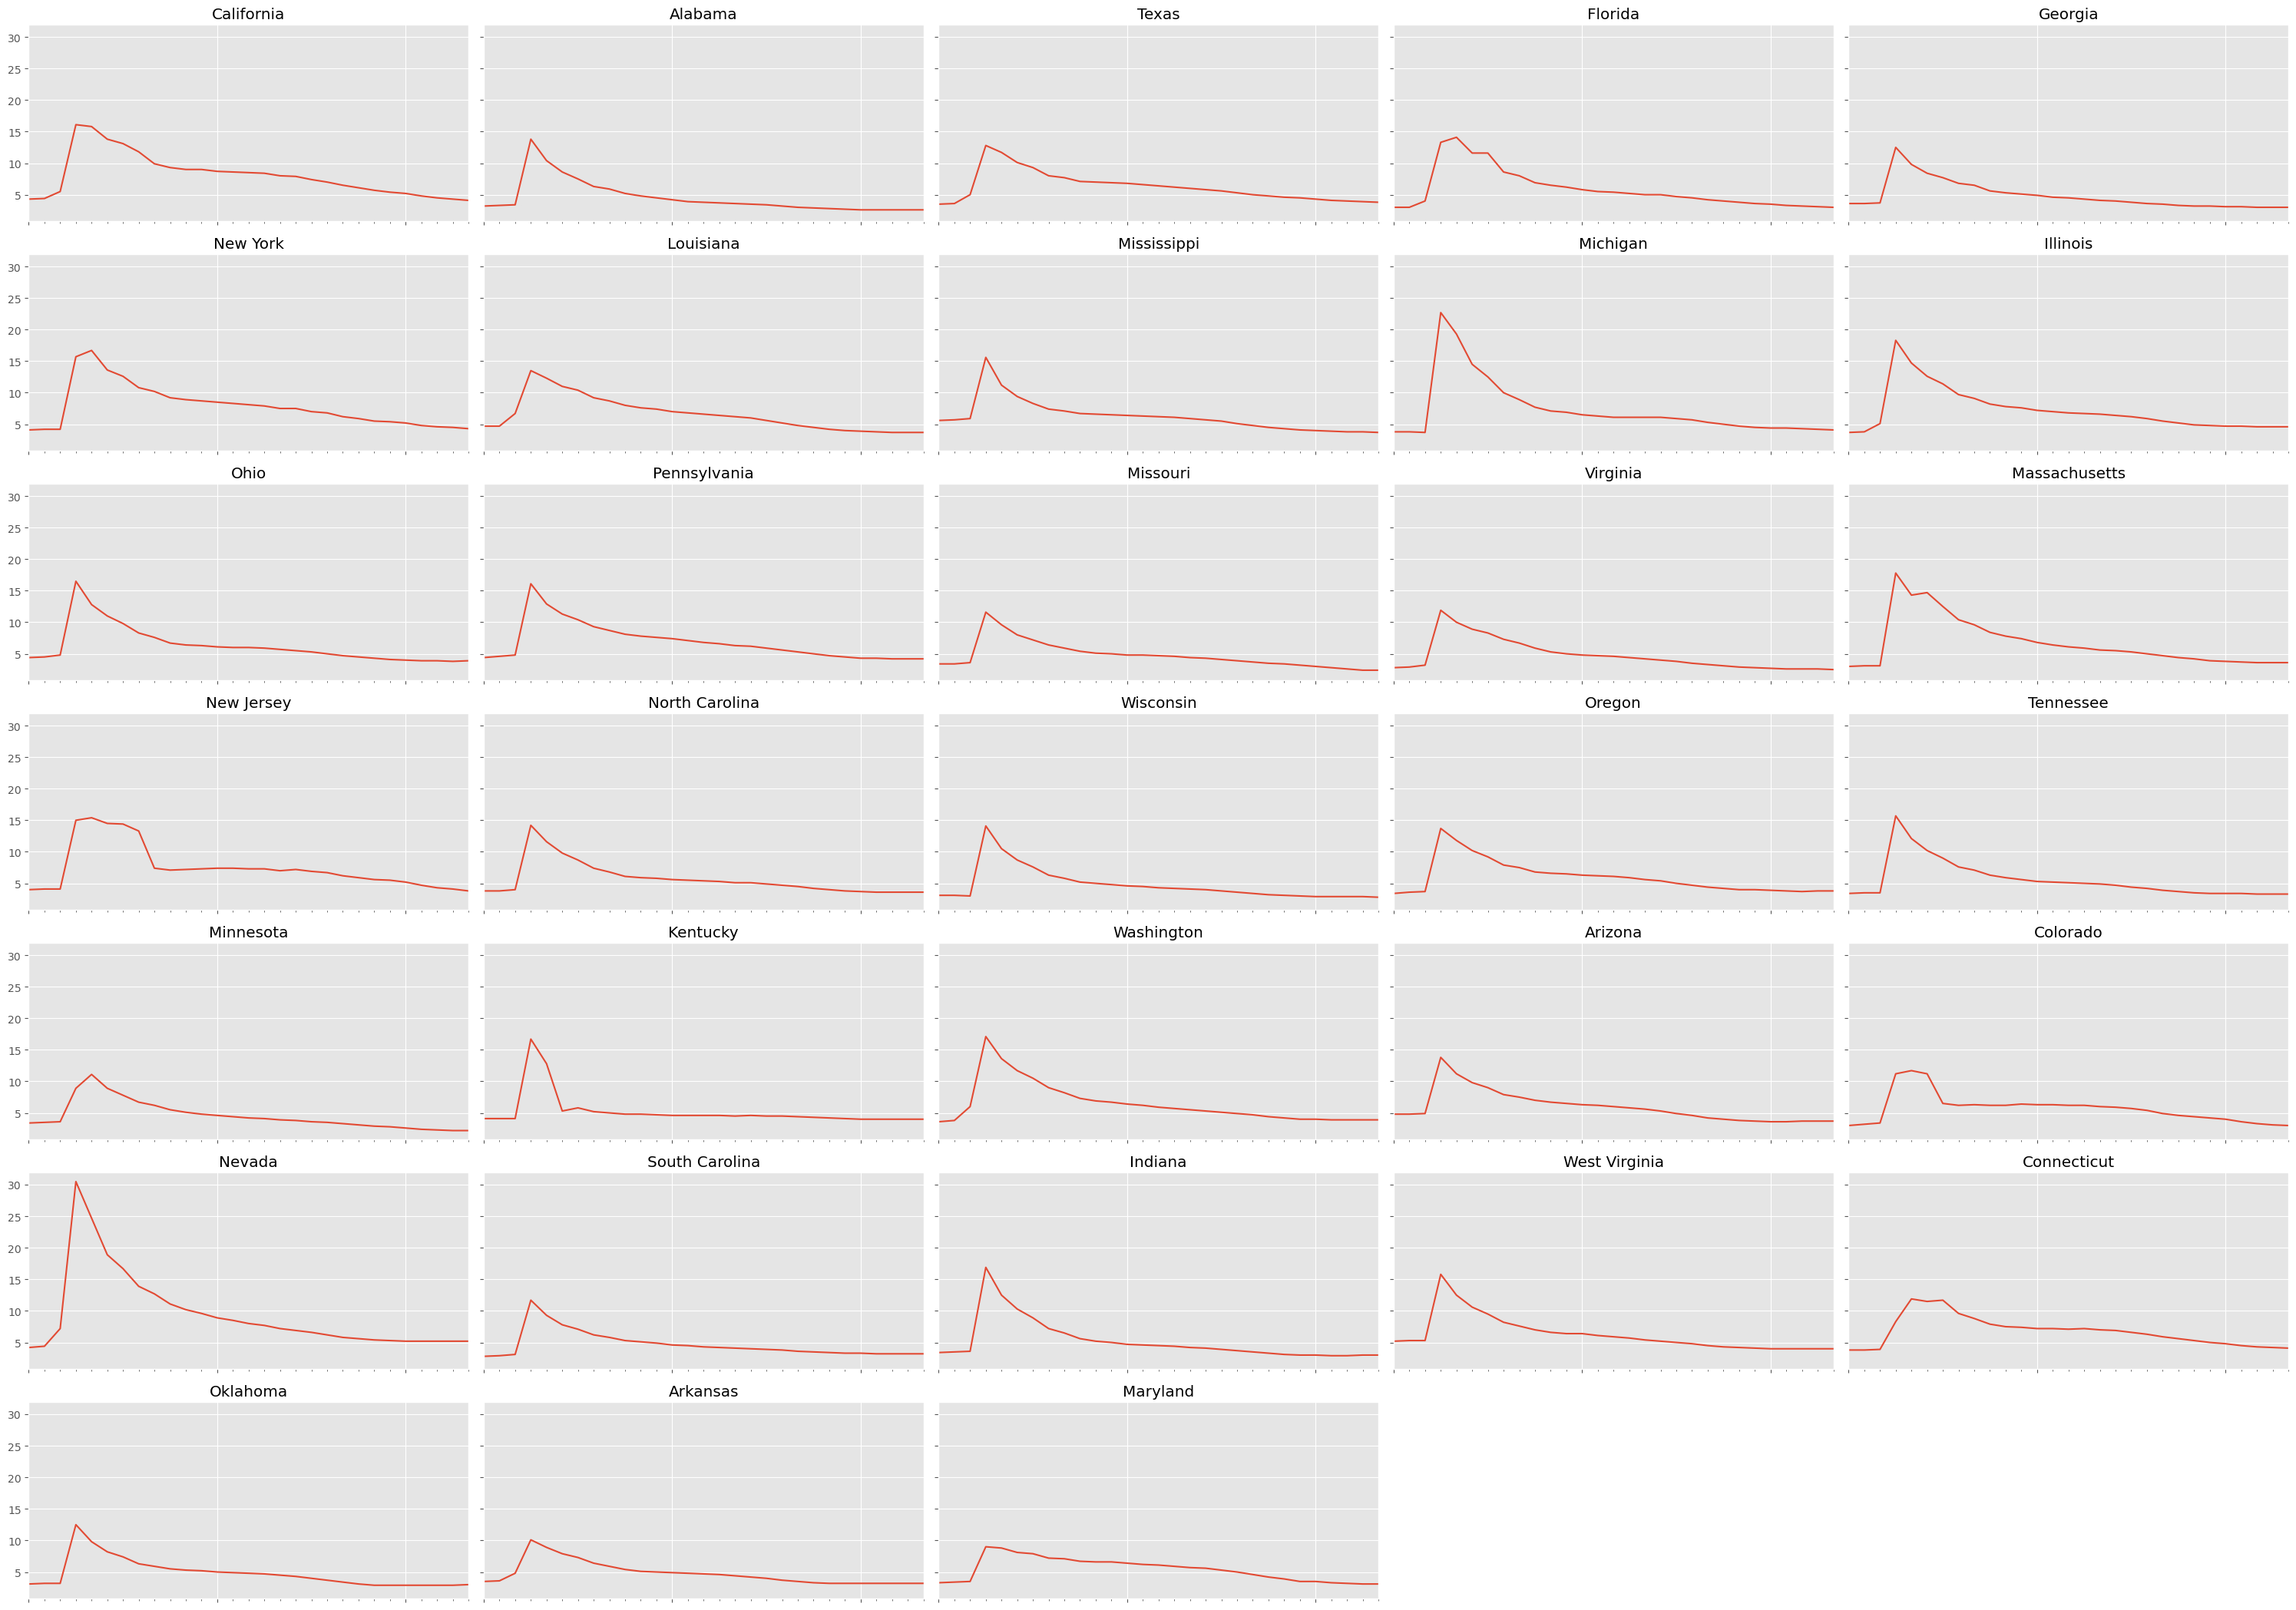

In [31]:
plot_states = [state for state in covid_unemp.columns
               if state not in ["the District of Columbia", "Puerto Rico"]]

fig, axs = plt.subplots(10, 5, sharex=True, sharey=True, figsize=(30, 30))
axs = axs.flatten()
for ax, state in zip(axs, plot_states):
    covid_unemp[state].plot(ax=ax, title=state, color=color_pal[0], legend=False)
for ax in axs[len(plot_states):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

Finally, a quick look at the joint movement of the first five states with `sns.pairplot` (more on seaborn in the next lecture).

In [32]:
covid_unemp.iloc[:, :5]

,California,Alabama,Texas,Florida,Georgia
2020-01-01,4.3,3.2,3.5,3.0,3.6
2020-02-01,4.4,3.3,3.6,3.0,3.6
2020-03-01,5.5,3.4,5.0,4.0,3.7
2020-04-01,16.1,13.8,12.8,13.3,12.5
2020-05-01,15.8,10.4,11.7,14.1,9.8
...,...,...,...,...,...
2022-01-01,5.2,2.6,4.3,3.5,3.1
2022-02-01,4.8,2.6,4.1,3.3,3.1
2022-03-01,4.5,2.6,4.0,3.2,3.0
2022-04-01,4.3,2.6,3.9,3.1,3.0


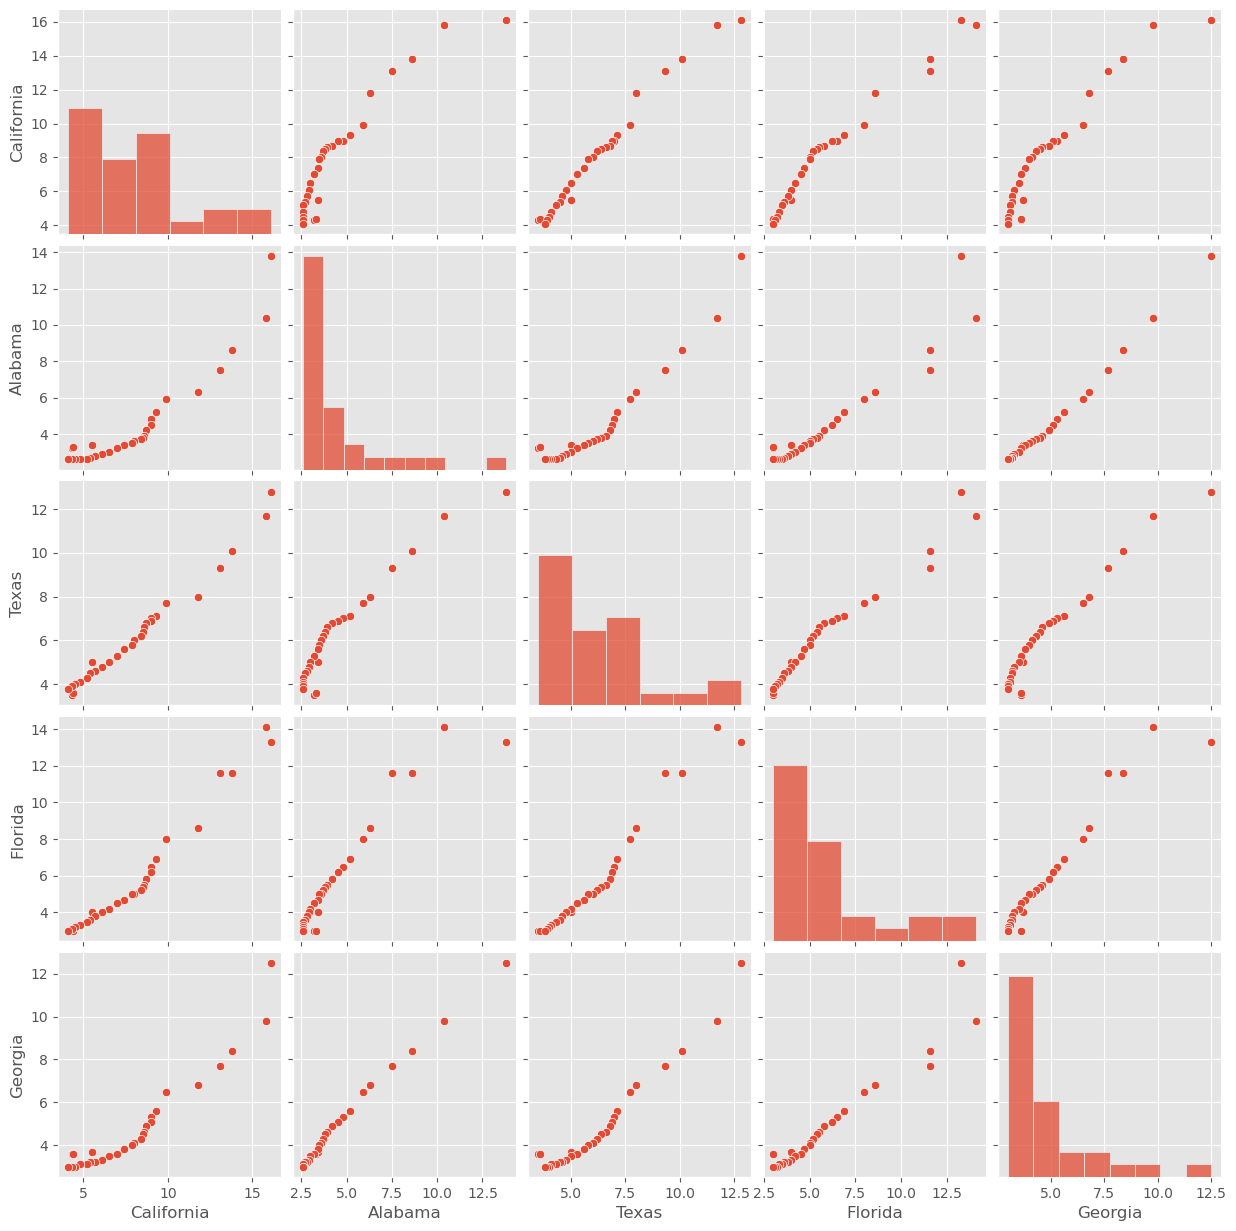

In [33]:
sns.pairplot(covid_unemp.iloc[:, :5])